# Computed error bound as a functions of truncating wavenumber $k_{\varepsilon}$

### Things we have to import

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gravmag import eqlayer, filters, transforms, convolve, utils, data_structures, inverse_distance
from gravmag.models import rectangular_prism as rp
from gravmag import plot_functions as plf
from gravmag import constants as cts

In [2]:
import pickle

In [3]:
from scipy.integrate import quad

In [4]:
# Function for evaluating the general error bound
def integrand(k, Dz, q):
    return np.exp(-2*Dz*k)*(k**(2*q-1))*((2*Dz)**(2*q))

### Load the computed model

In [5]:
model = pickle.load(open('model/model.pickle', 'rb'))

In [6]:
print('Model top: {} m | base: {} m'.format(np.min(model['z1']), np.max(model['z2'])))

Model top: 0.0 m | base: 600.001 m


In [7]:
mag_intensity = pickle.load(open('model/model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/model_mag_dec.pickle', 'rb'))

In [8]:
mag_inc

array([-10.2, -10.2, -10.2, ..., -10.2, -10.2, -10.2])

In [9]:
mag_dec

array([-19.8, -19.8, -19.8, ..., -19.8, -19.8, -19.8])

In [10]:
h_hat = utils.unit_vector(inc = mag_inc[0], dec = mag_dec[0])

In [11]:
# compute the Cartesian components of magnetization
mx, my, mz = utils.magnetization_components(
    np.vstack([mag_intensity, mag_inc, mag_dec]).T
)

In [13]:
# volume of the prisms forming the model
prisms_volume = utils.prisms_volume(model)

# total magnetic moment
total_moment = np.sum(mag_intensity*prisms_volume)

print('Total magnetic moment of the model: {:.3e} Am²'.format(total_moment))

Total magnetic moment of the model: 1.118e+11 Am²


In [14]:
# inclination (degrees)
I0 = -30

# declination (degrees)
D0 = -19

# Cartesian components of the main field
F_hat = utils.unit_vector(inc=I0, dec=D0)

# plot image generated with PyVista
<img src='model/model.gif' width='750' align='center'>

# plot image generated with PyVista
<img src='model/model_slice_y.gif' width='750' align='center'>

### Points were we compute the synthetic data

In [15]:
coordinates_grid = pickle.load(open('model/coordinates_grid.pickle', 'rb'))

In [16]:
print('Regular grid of coordinates on the horizontal plane {} m'.format(coordinates_grid['z']))

Regular grid of coordinates on the horizontal plane -150 m


In [17]:
# Grid spacing
dx, dy = data_structures.grid_xy_spacing(coordinates_grid['area'], coordinates_grid['shape'])

In [18]:
print(dx, dy)

40.13377926421405 36.474164133738604


In [19]:
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

### Synthetic magnetic field

In [20]:
bx = pickle.load(open('model/magnetic_field_component_bx.pickle', 'rb'))
by = pickle.load(open('model/magnetic_field_component_by.pickle', 'rb'))
bz = pickle.load(open('model/magnetic_field_component_bz.pickle', 'rb'))
rtp = pickle.load(open('model/rtp.pickle', 'rb'))

b_amp = np.sqrt(bx**2 + by**2 + bz**2)

# Compute the approximated total-field anomaly (Blakely, 1996, p. 179)
approx_tfa = F_hat[0]*bx + F_hat[1]*by + F_hat[2]*bz

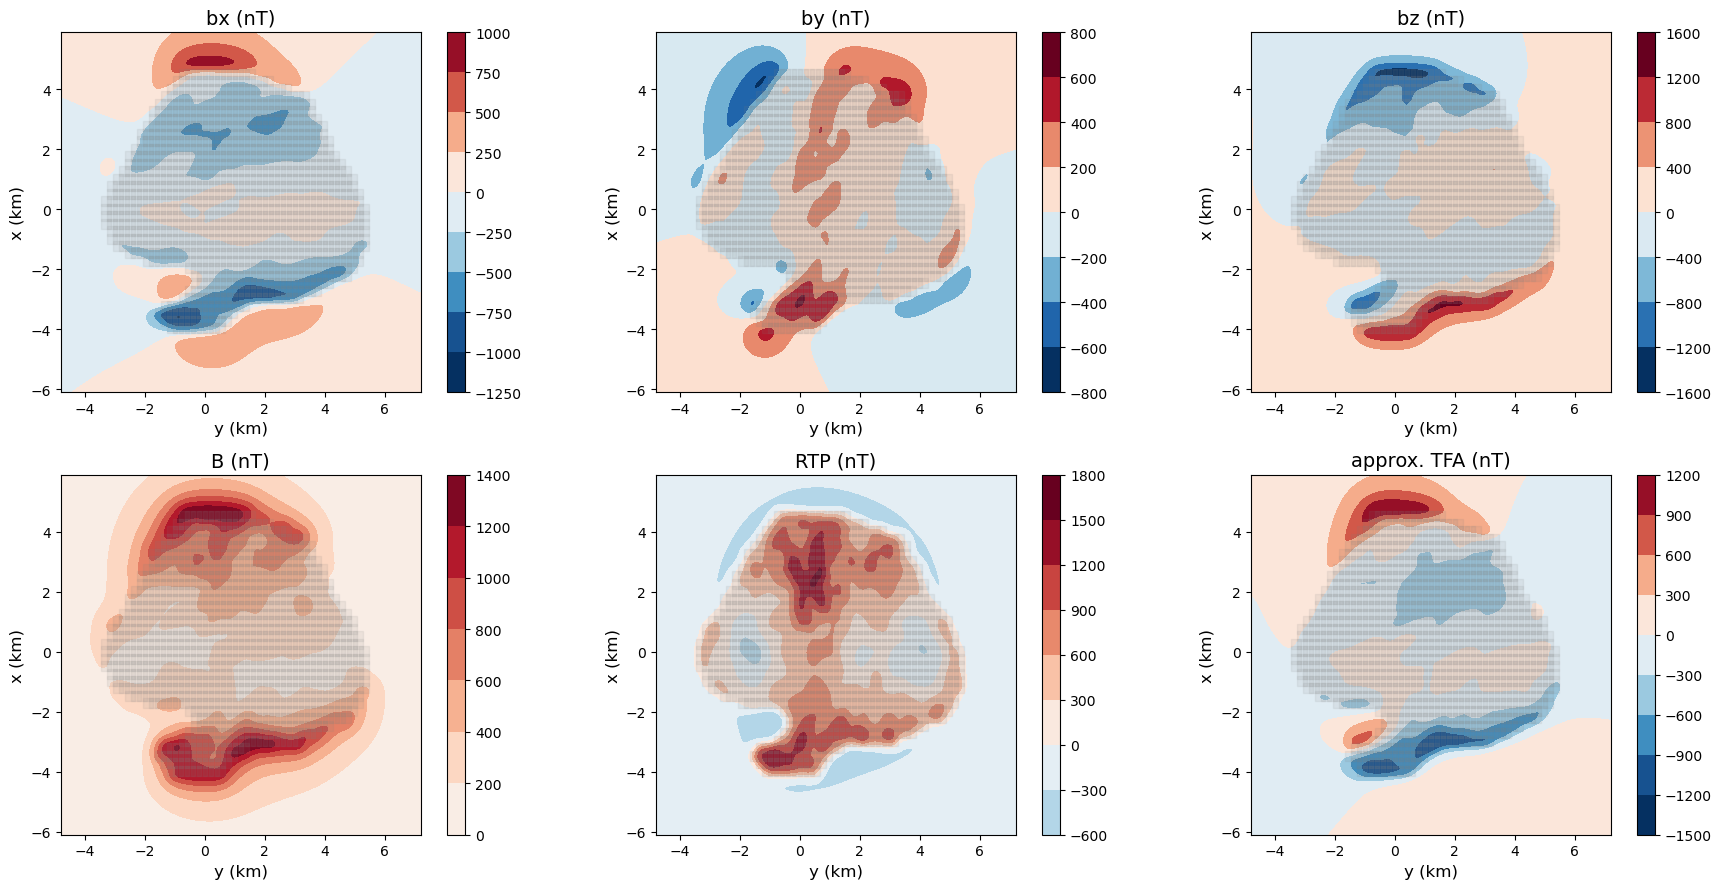

In [21]:
fields = [bx, by, bz, b_amp, rtp, approx_tfa]
windows = [1, 2, 3, 4, 5, 6]
titles = ['bx (nT)', 'by (nT)', 'bz (nT)', 
          'B (nT)', 'RTP (nT)', 'approx. TFA (nT)']

plt.figure(figsize=(18,9))

for w, window in enumerate(windows):
    bounds = np.max(np.abs(fields[w]))
    plt.subplot(2,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            data=fields[w], ordering='xy', shape=coordinates_grid['shape']
        ), 
        cmap='RdBu_r', vmin=-bounds, vmax=bounds)
    plt.colorbar()

    # horizontal projection of the model
    plt.scatter(
        x=0.5*(model['y1']+model['y2'])*0.001, 
        y=0.5*(model['x1']+model['x2'])*0.001,  
        s=50,
        c='gray',
        marker='s',
        alpha=0.1
    )
    
    plt.ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    plt.xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    plt.ylabel('x (km)', fontsize=12)
    plt.xlabel('y (km)', fontsize=12)

plt.tight_layout()

plt.show()

### Neumann's equivalent layer

In [22]:
# set a layer that crosses the sources
z_layer = 200

In [23]:
print('The distance from coordinates grid to layer is {} m'.format(z_layer-coordinates_grid['z']))

The distance from coordinates grid to layer is 350 m


In [24]:
# compute the pseudogravity anomaly above the sources
pseudo_grav = rp.grav(
    coordinates=data_structures.grid_xy_to_full_flatten(
        grid=coordinates_grid,
        ordering='xy'
    ),
    prisms=model, 
    density=mag_intensity, 
    field='z', 
    scale=False
)

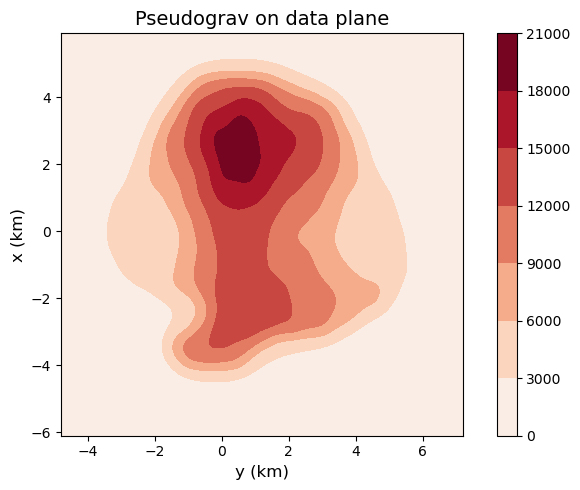

In [25]:
plt.figure(figsize=(7,5))

bounds = np.max(np.abs(pseudo_grav))

plt.title('Pseudograv on data plane', fontsize=14)
plt.axis('scaled')
plt.contourf(
    Y*0.001, X*0.001,
    data_structures.grid_xy_full_flatten_to_matrix(
        data = pseudo_grav, ordering='xy', shape=coordinates_grid['shape']
    ),  
    cmap='RdBu_r',
    vmin = -bounds, vmax = bounds
)
plt.colorbar()
plt.ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
plt.xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
plt.xlabel('y (km)', fontsize=12)
plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()

In [26]:
# compute 2D Fourier transform of pseudogravity anomaly with padding
FT_pseudo_grav = transforms.DFT(
    data = data_structures.grid_xy_full_flatten_to_matrix(
        data = pseudo_grav, ordering='xy', shape=coordinates_grid['shape']
    ), 
    pad_mode='linear_ramp'
)

In [27]:
# compute wavenumbers
wavenumbers = data_structures.grid_wavenumbers(grid = coordinates_grid, pad = True)

In [28]:
print('Max/min wavenumbers along x: {:.5f}/{:.5f} | y: {:.5f}/{:.5f}'.format(
    np.min(wavenumbers['x']), np.max(wavenumbers['x']), np.min(wavenumbers['y']), np.max(wavenumbers['y'])
))

Max/min wavenumbers along x: -0.07828/0.07810 | y: -0.08613/0.08596


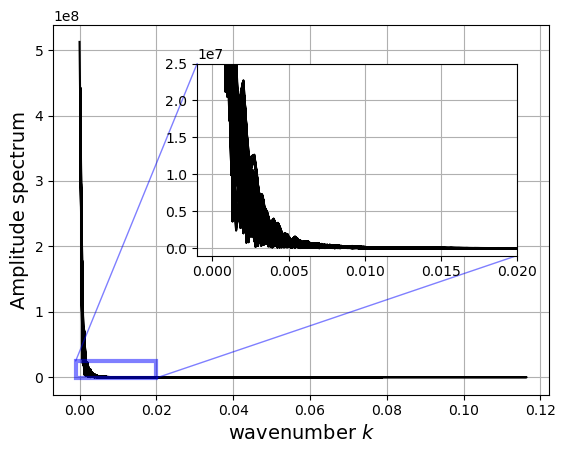

In [56]:
fig, ax = plt.subplots()

ax.plot(
    data_structures.grid_xy_full_matrix_to_flatten(
        grid = wavenumbers['z'], ordering = 'xy'
    ),
    data_structures.grid_xy_full_matrix_to_flatten(
        grid = np.abs(FT_pseudo_grav), ordering = 'xy'
    ),
    'k-'
)
ax.set_xlabel('wavenumber $k$', fontsize=14)
ax.set_ylabel('Amplitude spectrum', fontsize=14)
ax.grid()

# # inset axes
#inset = fig.add_axes([left, bottom, width, height])
inset = fig.add_axes([0.35, 0.4, 0.50, 0.40])

inset.plot(
    data_structures.grid_xy_full_matrix_to_flatten(
        grid = wavenumbers['z'], ordering = 'xy'
    ),
    data_structures.grid_xy_full_matrix_to_flatten(
        grid = np.abs(FT_pseudo_grav), ordering = 'xy'
    ),
    'k-'
)

# # subregion of the original image
inset.set_xlim(-0.001, 0.02)
inset.set_ylim(-0.01e8, 0.25e8)
#inset.set_xticklabels([])
#inset.set_yticklabels([])
inset.grid()

ax.indicate_inset_zoom(inset, edgecolor="blue", linewidth=3)

plt.show()

In [30]:
# compute the SEDM
R2 = inverse_distance.sedm_BTTB(
    data_grid = coordinates_grid, 
    delta_z = z_layer - coordinates_grid['z'],
    ordering = 'xy'
)

In [31]:
# compute the tensor components
Tensor = inverse_distance.grad_tensor_BTTB(
    data_grid = coordinates_grid,
    delta_z = z_layer - coordinates_grid['z'],
    SEDM = R2,
    ordering = 'xy',
    components=['xx', 'xy', 'xz', 'yy', 'yz', 'zz']
)

In [32]:
# compute the eigenvalues matrices
L_Tensor = dict()
for component in ['xx', 'xy', 'xz', 'yy', 'yz', 'zz']:
    L_Tensor[component] = convolve.eigenvalues_BCCB(BTTB_metadata=Tensor[component])

In [33]:
# directional factor to compute the approximated total-field anomaly
a = utils.directional_factors(t=h_hat, u=F_hat)

In [34]:
# define the continuation filter
downward_continuation = filters.continuation(wavenumbers = wavenumbers, dz = z_layer-coordinates_grid['z'])

In [35]:
# define the approximated total-field anomaly fit versus truncating wavenumber
#k_epsilons = np.linspace(4e-3, 4e-2, 50)
k_epsilons = np.linspace(1e-7, 6e-2, 500)
data_fits = []
for k_epsilon in k_epsilons:
    # define the low-pass filter
    lowpass = filters.cuttof_frequency(wavenumbers = wavenumbers, max_freq = k_epsilon)
    # compute the downward continued field in Fourier domain
    FT_pseudo_grav_downward_layer = convolve.compute(FT_pseudo_grav, [lowpass, downward_continuation])
    # transform the downward continued field to space domain
    pseudo_grav_downward_layer = transforms.IDFT(FT_pseudo_grav_downward_layer, unpad=True)
    # theoretical equivalent layer
    p_theoretical = ((dx*dy*cts.CM)/(2*np.pi))*pseudo_grav_downward_layer
    # approximated total-field anomaly
    approx_tfa_predicted = np.zeros_like(bz)
    for component in ['xx', 'xy', 'xz', 'yy', 'yz']:
        approx_tfa_predicted[:] += convolve.product_BCCB_vector(
            eigenvalues = a[component]*L_Tensor[component],
            ordering = 'row',
            v = data_structures.grid_xy_full_matrix_to_flatten(
                grid = p_theoretical, ordering = 'xy'
            )
        )
    approx_tfa_predicted[:] *= cts.T2NT
    # compute the data fit
    residuals = approx_tfa_predicted - approx_tfa
    data_fits.append(np.sum(residuals*residuals)/residuals.size)

In [36]:
# generic error bound
generic_error_bound = []
for k_epsilon in k_epsilons:
    result, error = quad(integrand, k_epsilon, np.inf, args=(z_layer-coordinates_grid['z'], 2))
    generic_error_bound.append((2*np.pi*total_moment*total_moment)*result)

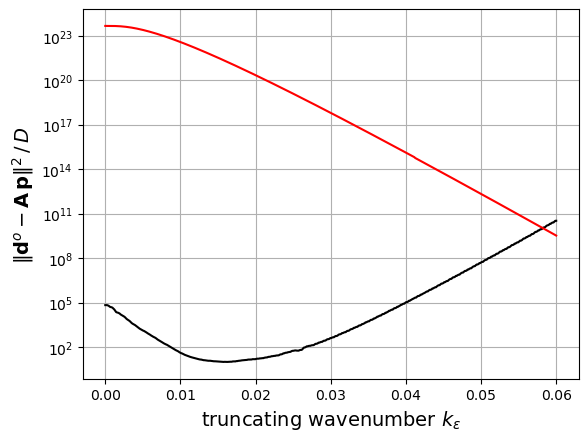

In [37]:
fig, ax = plt.subplots()

ax.plot(k_epsilons, data_fits, 'k-')
ax.plot(k_epsilons, generic_error_bound, 'r-')
ax.set_xlabel('truncating wavenumber $k_{\\varepsilon}$', fontsize=14)
ax.set_ylabel('$\| \mathbf{d}^{o} - \mathbf{A} \, \mathbf{p}\|^{2} \slash D$', fontsize=14)
ax.set_yscale('log')
ax.grid()

# # inset axes
# #inset = fig.add_axes([left, bottom, width, height])
# inset = fig.add_axes([0.35, 0.4, 0.50, 0.40])

# inset.plot(
#     data_structures.grid_xy_full_matrix_to_flatten(
#         grid = wavenumbers['z'], ordering = 'xy'
#     ),
#     data_structures.grid_xy_full_matrix_to_flatten(
#         grid = np.abs(FT_pseudo_grav), ordering = 'xy'
#     ),
#     'k-'
# )

# # # subregion of the original image
# inset.set_xlim(-0.001, 0.05)
# inset.set_ylim(-0.25e8, 1e8)
# #inset.set_xticklabels([])
# #inset.set_yticklabels([])
# inset.grid()

# ax.indicate_inset_zoom(inset, edgecolor="blue", linewidth=3)

plt.show()

In [38]:
k_epsilon_optimum = k_epsilons[np.argmin(data_fits)]

In [39]:
print('Truncating wavenumber leading to minimum error: {:.5f}'.format(k_epsilon_optimum))

Truncating wavenumber leading to minimum error: 0.01575


In [40]:
# define the low-pass filter
lowpass = filters.cuttof_frequency(wavenumbers = wavenumbers, max_freq = k_epsilon_optimum)

In [41]:
# compute the downward continued field in Fourier domain
FT_pseudo_grav_downward_layer = convolve.compute(FT_pseudo_grav, [lowpass, downward_continuation])

In [42]:
# transform the downward continued field to space domain
pseudo_grav_downward_layer = transforms.IDFT(FT_pseudo_grav_downward_layer, unpad=True)

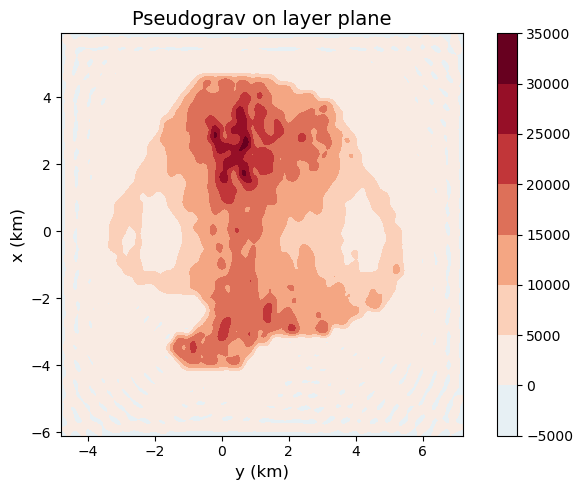

In [43]:
plt.figure(figsize=(7,5))

bounds = np.max(np.abs(pseudo_grav_downward_layer))

plt.title('Pseudograv on layer plane', fontsize=14)
plt.axis('scaled')
plt.contourf(
    Y*0.001, X*0.001,
    pseudo_grav_downward_layer,  
    cmap='RdBu_r',
    vmin = -bounds, vmax = bounds
)
plt.colorbar()
plt.ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
plt.xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
plt.xlabel('y (km)', fontsize=12)
plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()

In [44]:
# theoretical equivalent layer
p_theoretical = ((dx*dy*cts.CM)/(2*np.pi))*pseudo_grav_downward_layer

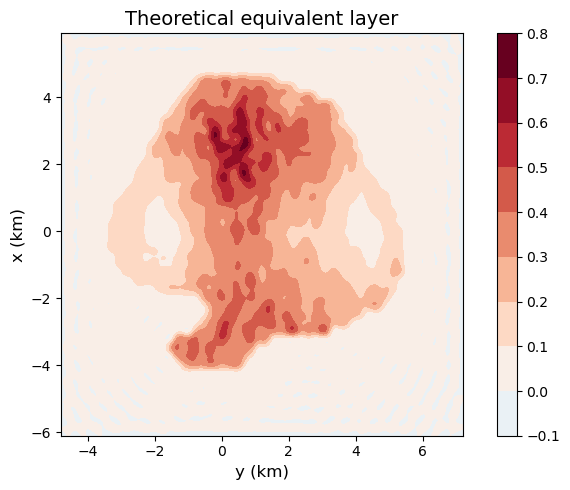

In [45]:
plt.figure(figsize=(7,5))

bounds = np.max(np.abs(p_theoretical))

plt.title('Theoretical equivalent layer', fontsize=14)
plt.axis('scaled')
plt.contourf(
    Y*0.001, X*0.001,
    p_theoretical,  
    cmap='RdBu_r',
    vmin = -bounds, vmax = bounds
)
plt.colorbar()
plt.ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
plt.xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
plt.xlabel('y (km)', fontsize=12)
plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()

### Magnetic field predicted by the theoretical equivalent layer

In [46]:
# magnetic field components
titles = ['bx (nT)', 'by (nT)', 'bz (nT)', 
          'B (nT)', 'RTP (nT)', 'approx. TFA (nT)']

In [47]:
# list for storing the predicted magnetic field components
predicted_fields = []

In [48]:
# magnetic induction field component x
result = np.zeros_like(bx)

for F_component, component in zip(F_hat, ['xx', 'xy', 'xz']):
    result[:] += F_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = data_structures.grid_xy_full_matrix_to_flatten(
            grid = p_theoretical, ordering = 'xy'
        )
    )

predicted_fields.append(cts.T2NT * result)

# magnetic induction field component y
result = np.zeros_like(by)

for F_component, component in zip(F_hat, ['xy', 'yy', 'yz']):
    result[:] += F_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = data_structures.grid_xy_full_matrix_to_flatten(
            grid = p_theoretical, ordering = 'xy'
        )
    )

predicted_fields.append(cts.T2NT * result)

# magnetic induction field component z
result = np.zeros_like(bz)

for F_component, component in zip(F_hat, ['xz', 'yz', 'zz']):
    result[:] += F_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = data_structures.grid_xy_full_matrix_to_flatten(
            grid = p_theoretical, ordering = 'xy'
        )
    )

predicted_fields.append(cts.T2NT * result)

In [49]:
# amplitude of anomalous B field
predicted_fields.append(
    np.sqrt(predicted_fields[0]**2 + predicted_fields[1]**2 + predicted_fields[2]**2)
)

In [50]:
# reduction to the pole
result = convolve.product_BCCB_vector(
    eigenvalues = L_Tensor['zz'],
    ordering = 'row',
    v = data_structures.grid_xy_full_matrix_to_flatten(
        grid = p_theoretical, ordering = 'xy'
    )
)

predicted_fields.append(cts.T2NT * result)

In [51]:
# approximated total-field anomaly
result = np.zeros_like(bz)

for component in ['xx', 'xy', 'xz', 'yy', 'yz']:
    result[:] += convolve.product_BCCB_vector(
        eigenvalues = a[component]*L_Tensor[component],
        ordering = 'row',
        v = data_structures.grid_xy_full_matrix_to_flatten(
            grid = p_theoretical, ordering = 'xy'
        )
    )

predicted_fields.append(cts.T2NT * result)

### Plot the results

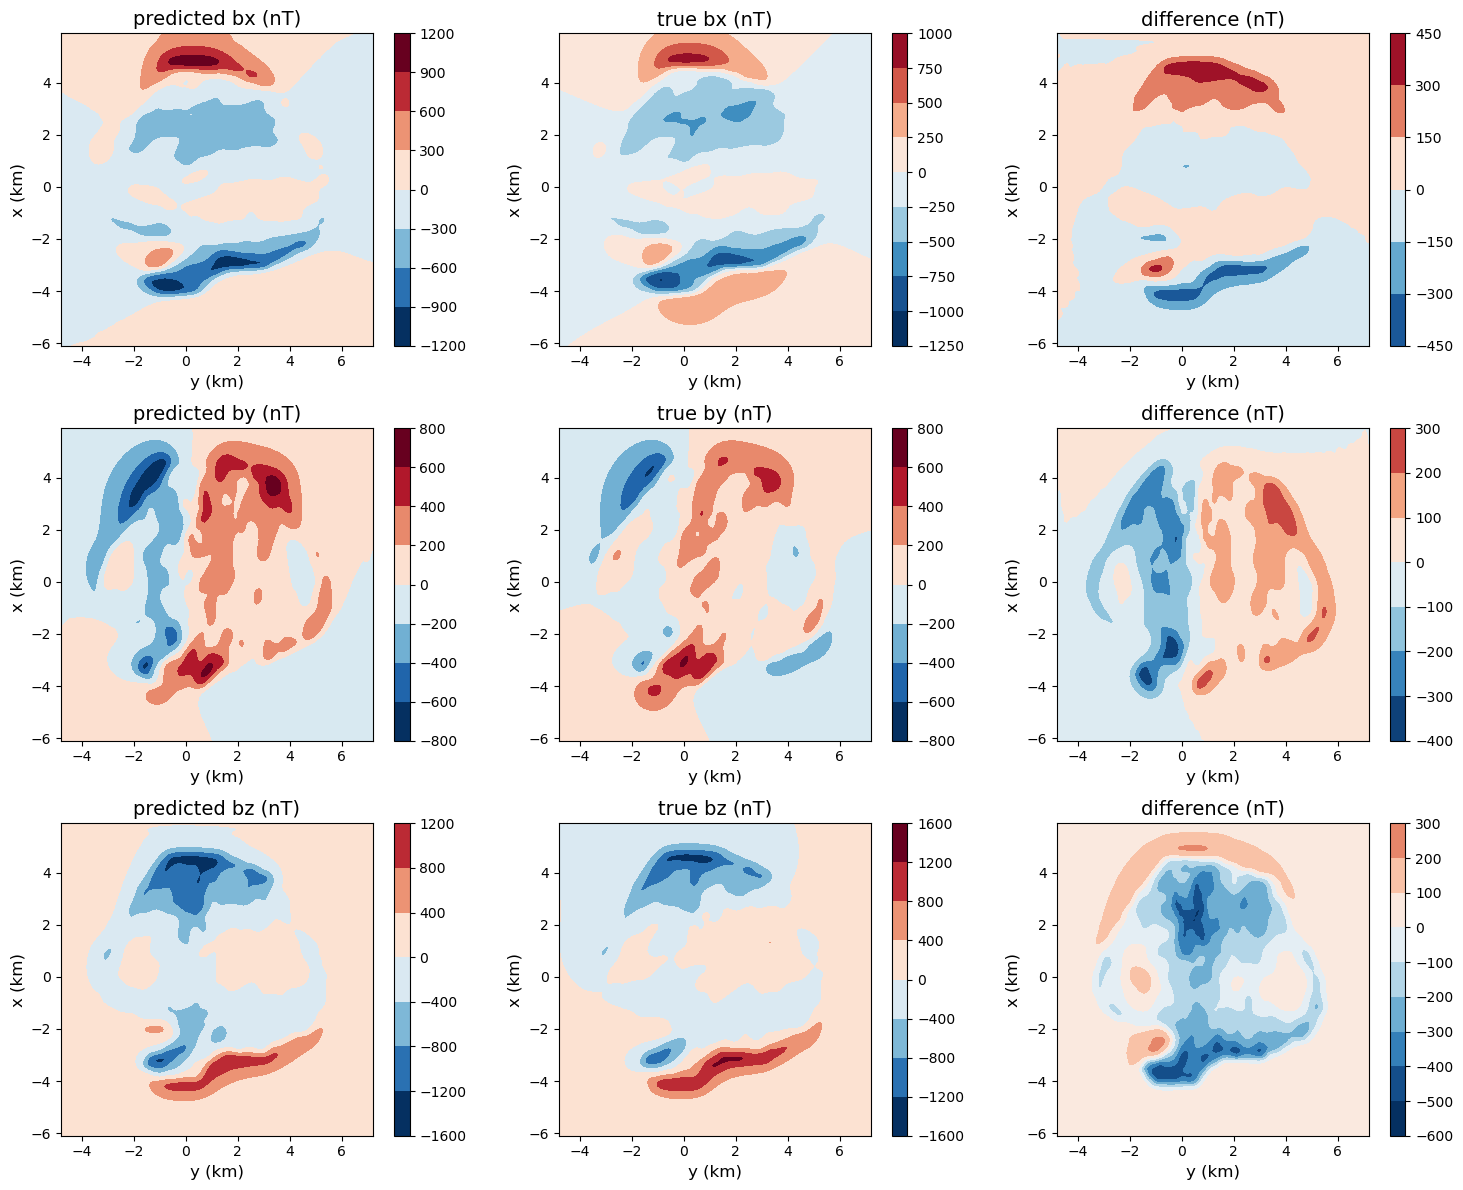

In [52]:
field_names = ['bx', 'by', 'bz']

true_fields = [bx, by, bz]

bounds, diffs = plf.bounds_diffs(predicted_fields[:3], true_fields)

fields = plf.fields_list(predicted_fields[:3], true_fields, diffs)

titles = []
for name in field_names:
    titles.append('predicted {} (nT)'.format(name))
    titles.append('true {} (nT)'.format(name))
    titles.append('difference (nT)')

windows = [i for i in range(1,10)]

plt.figure(figsize=(15,12))

for w, window in enumerate(windows):

    plt.subplot(3,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            fields[w], ordering='xy', shape=coordinates_grid['shape']
        ), 
        cmap='RdBu_r',
        vmin = -bounds[w], vmax = bounds[w]
    )
    plt.colorbar()
    plt.ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    plt.xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    plt.xlabel('y (km)', fontsize=12)
    plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()

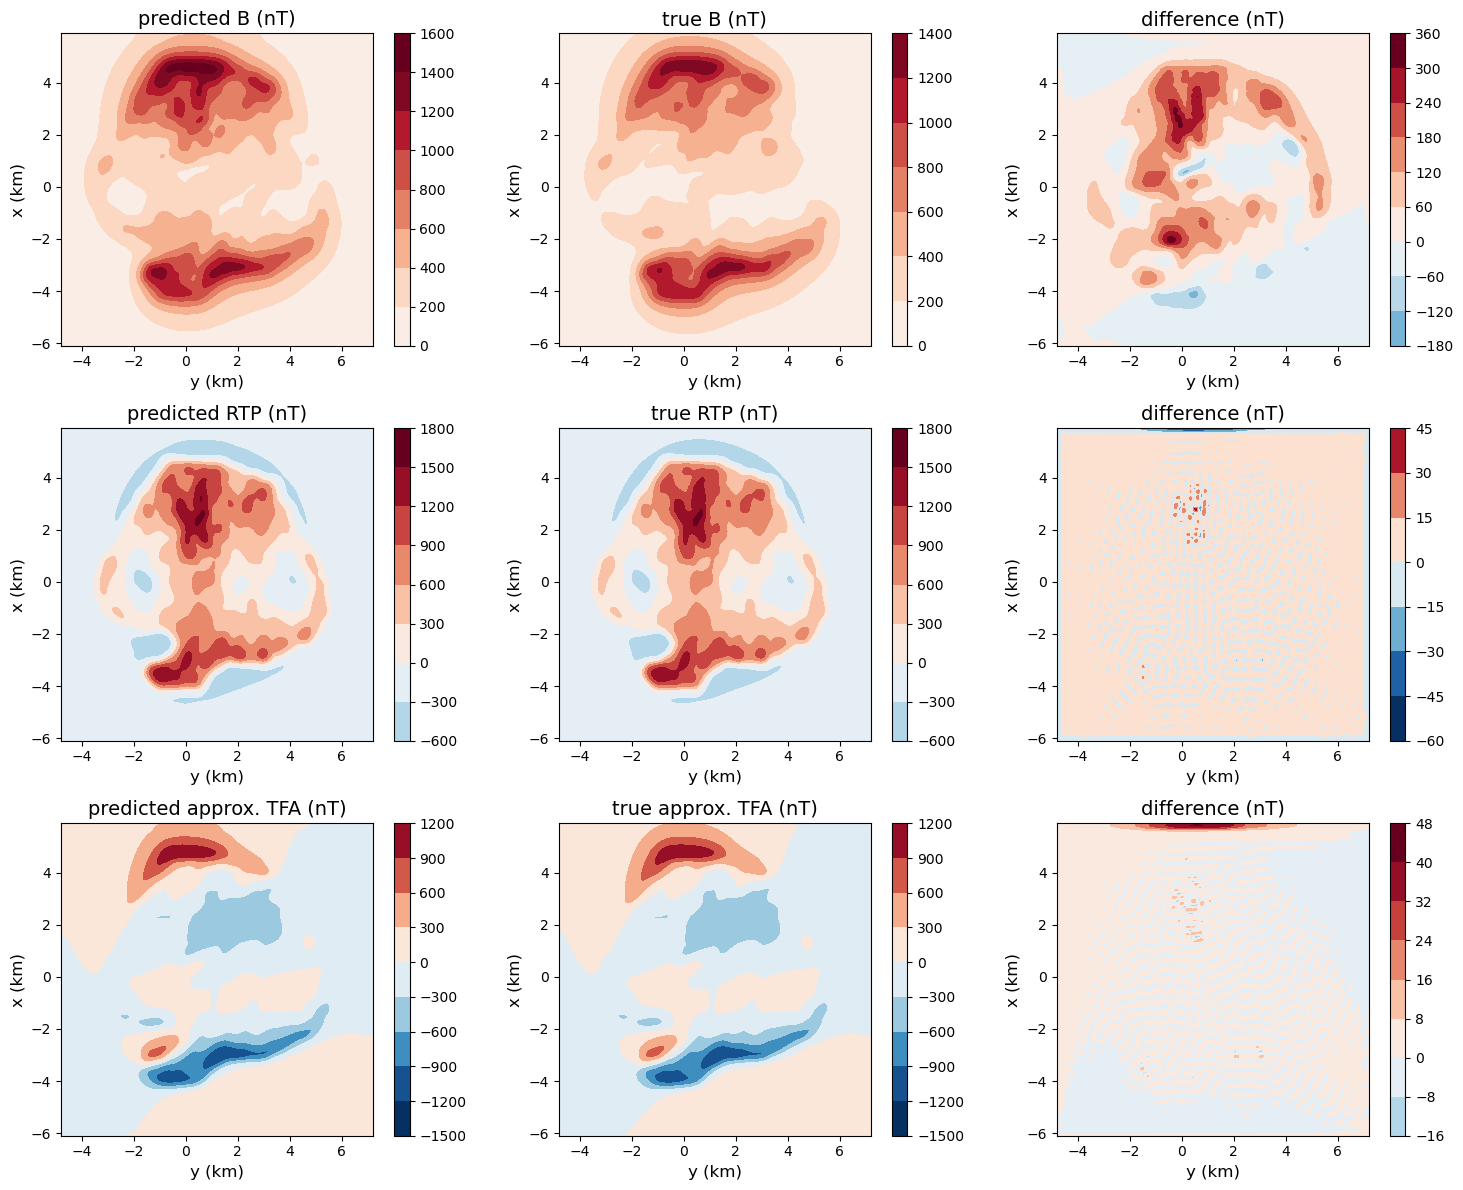

In [53]:
field_names = ['B', 'RTP', 'approx. TFA']

true_fields = [b_amp, rtp, approx_tfa]

bounds, diffs = plf.bounds_diffs(predicted_fields[3:], true_fields)

fields = plf.fields_list(predicted_fields[3:], true_fields, diffs)

titles = []
for name in field_names:
    titles.append('predicted {} (nT)'.format(name))
    titles.append('true {} (nT)'.format(name))
    titles.append('difference (nT)')

windows = [i for i in range(1,10)]

plt.figure(figsize=(15,12))

for w, window in enumerate(windows):

    plt.subplot(3,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            fields[w], ordering='xy', shape=coordinates_grid['shape']
        ), 
        cmap='RdBu_r',
        vmin = -bounds[w], vmax = bounds[w]
    )
    plt.colorbar()
    plt.ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    plt.xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    plt.xlabel('y (km)', fontsize=12)
    plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()